# 03. Data Checks, EDA, and Graph Statistics

This notebook runs the formal data-quality checks and describes label balance, degree, edge types, centrality, clustering, homophily, and a readable network sample.


In [1]:
from pathlib import Path
import os
import sys
import warnings

import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, display


def find_project_root(start: Path) -> Path:
    """Find the repository root whether Jupyter starts there or in notebooks/."""
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root.")


ROOT = find_project_root(Path.cwd())
os.chdir(ROOT)
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
print(f"Project root: {ROOT}")


Project root: C:\Users\Jimi\Desktop\github-social-network


## Essential analysis logic

The reusable implementation is in `src/graph_analysis.py` and `src/run_core_analysis.py`. The main quantities are calculated directly from the validated graph:

```python
degrees = [degree for _, degree in G.degree()]
mean_degree = 2 * G.number_of_edges() / G.number_of_nodes()
same_label = sum(labels[u] == labels[v] for u, v in G.edges())
homophily = same_label / G.number_of_edges()
```

Centrality tables use degree, PageRank, clustering coefficient, and sampled betweenness. Betweenness is approximated with 100 sources because exact all-pairs computation is not practical for 37,700 nodes.


In [2]:
from data_loader import load_dataset
from graph_analysis import compute_basic_stats, compute_edge_type_counts, compute_homophily
from run_core_analysis import main as run_core_analysis

run_core_analysis()

G, _, labels_df, labels_dict = load_dataset(ROOT / "data")
degree_values = np.fromiter((degree for _, degree in G.degree()), dtype=np.int64)
sanity_check = {
    **compute_basic_stats(G, labels_df),
    **compute_homophily(G, labels_dict),
    "median_degree": float(np.median(degree_values)),
    "max_degree": int(degree_values.max()),
}
display(pd.DataFrame([sanity_check]))
display(pd.DataFrame([
    {"edge_type": key, "count": value}
    for key, value in compute_edge_type_counts(G, labels_dict).items()
]))


Computing centralities ...


Core analysis completed.
 num_nodes  num_edges  density  average_degree  num_connected_components  largest_component_size  largest_component_ratio  labeled_nodes_total  labeled_nodes_in_graph  labeled_node_ratio  homophily_rate  same_label_edges  different_label_edges  labeled_edges
     37700     289003 0.000407       15.331724                         1                   37700                      1.0                37700                   37700                 1.0        0.845344            244307                  44696         289003
 number_of_communities  modularity  largest_community_size  median_community_size  size_weighted_mean_purity
                    31    0.453448                    8732                    9.0                   0.829788


,num_nodes,num_edges,density,average_degree,num_connected_components,largest_component_size,largest_component_ratio,labeled_nodes_total,labeled_nodes_in_graph,labeled_node_ratio,homophily_rate,same_label_edges,different_label_edges,labeled_edges,median_degree,max_degree
0,37700,289003,0.000407,15.331724,1,37700,1.0,37700,37700,1.0,0.845344,244307,44696,289003,6.0,9458


,edge_type,count
0,web_web,224623
1,ml_ml,19684
2,web_ml,44696
3,missing_label,0


## Saved tables

These tables are regenerated by the cell above, so this notebook is executable from a fresh kernel without relying on notebook 02.


In [3]:
quality = pd.read_csv(ROOT / "outputs/tables/data_quality_checks.csv")
labels = pd.read_csv(ROOT / "outputs/tables/label_distribution.csv")
centrality = pd.read_csv(ROOT / "outputs/tables/centrality_top_developers.csv")
overlap = pd.read_csv(ROOT / "outputs/tables/centrality_top_overlap.csv")

display(quality)
display(labels)
display(centrality.head(12))
display(overlap.round(4))
assert quality["passed"].all()


,check,value,passed
0,raw_edge_rows,289003,True
1,graph_nodes,37700,True
2,graph_edges,289003,True
3,self_loops,0,True
4,duplicate_undirected_edges,0,True
5,duplicate_label_ids,0,True
6,missing_labels,0,True
7,all_graph_nodes_labeled,1,True
8,connected_components,1,True


,label,count,class_name,ratio
0,0,27961,Web,0.741671
1,1,9739,Machine Learning,0.258329


,metric,rank,node_id,developer_name,field,score,degree,pagerank,betweenness_approx,clustering_coefficient
0,Degree Centrality,1,31890,dalinhuang99,Web,0.250882,9458,0.016514,0.238360,0.001413
1,Degree Centrality,2,27803,nfultz,Web,0.187936,7085,0.011451,0.270590,0.003199
2,Degree Centrality,3,35773,addyosmani,Web,0.088172,3324,0.004919,0.052829,0.004121
3,Degree Centrality,4,19222,Bunlong,Web,0.078464,2958,0.004669,0.063271,0.006373
4,Degree Centrality,5,13638,gabrielpconceicao,Web,0.065466,2468,0.003875,0.036141,0.006492
5,Degree Centrality,6,36652,rfthusn,Web,0.062150,2343,0.003799,0.028997,0.003391
6,Degree Centrality,7,18163,nelsonic,Web,0.051036,1924,0.003381,0.021605,0.001463
7,Degree Centrality,8,9051,getify,Web,0.047667,1797,0.002722,0.020348,0.003654
8,Degree Centrality,9,35008,mdo,Web,0.041672,1571,0.002338,0.018111,0.004686
9,Degree Centrality,10,10001,ronenhamias,Web,0.041593,1568,0.002665,0.035892,0.006944


,metric_a,metric_b,top_k,intersection_count,jaccard_overlap
0,Degree Centrality,PageRank,20,20,1.0000
1,Degree Centrality,"Betweenness Centrality (approx., k=100)",20,15,0.6000
2,Degree Centrality,Clustering Coefficient,20,0,0.0000
3,Degree Centrality,HITS Hub,20,17,0.7391
4,PageRank,"Betweenness Centrality (approx., k=100)",20,15,0.6000
5,PageRank,Clustering Coefficient,20,0,0.0000
6,PageRank,HITS Hub,20,17,0.7391
7,"Betweenness Centrality (approx., k=100)",Clustering Coefficient,20,0,0.0000
8,"Betweenness Centrality (approx., k=100)",HITS Hub,20,14,0.5385
9,Clustering Coefficient,HITS Hub,20,0,0.0000


The class distribution is imbalanced, so later classifiers report Balanced Accuracy, Macro F1, and ROC-AUC in addition to Accuracy. Same-field edges are common, but this descriptive pattern does not establish causality.

## Figures


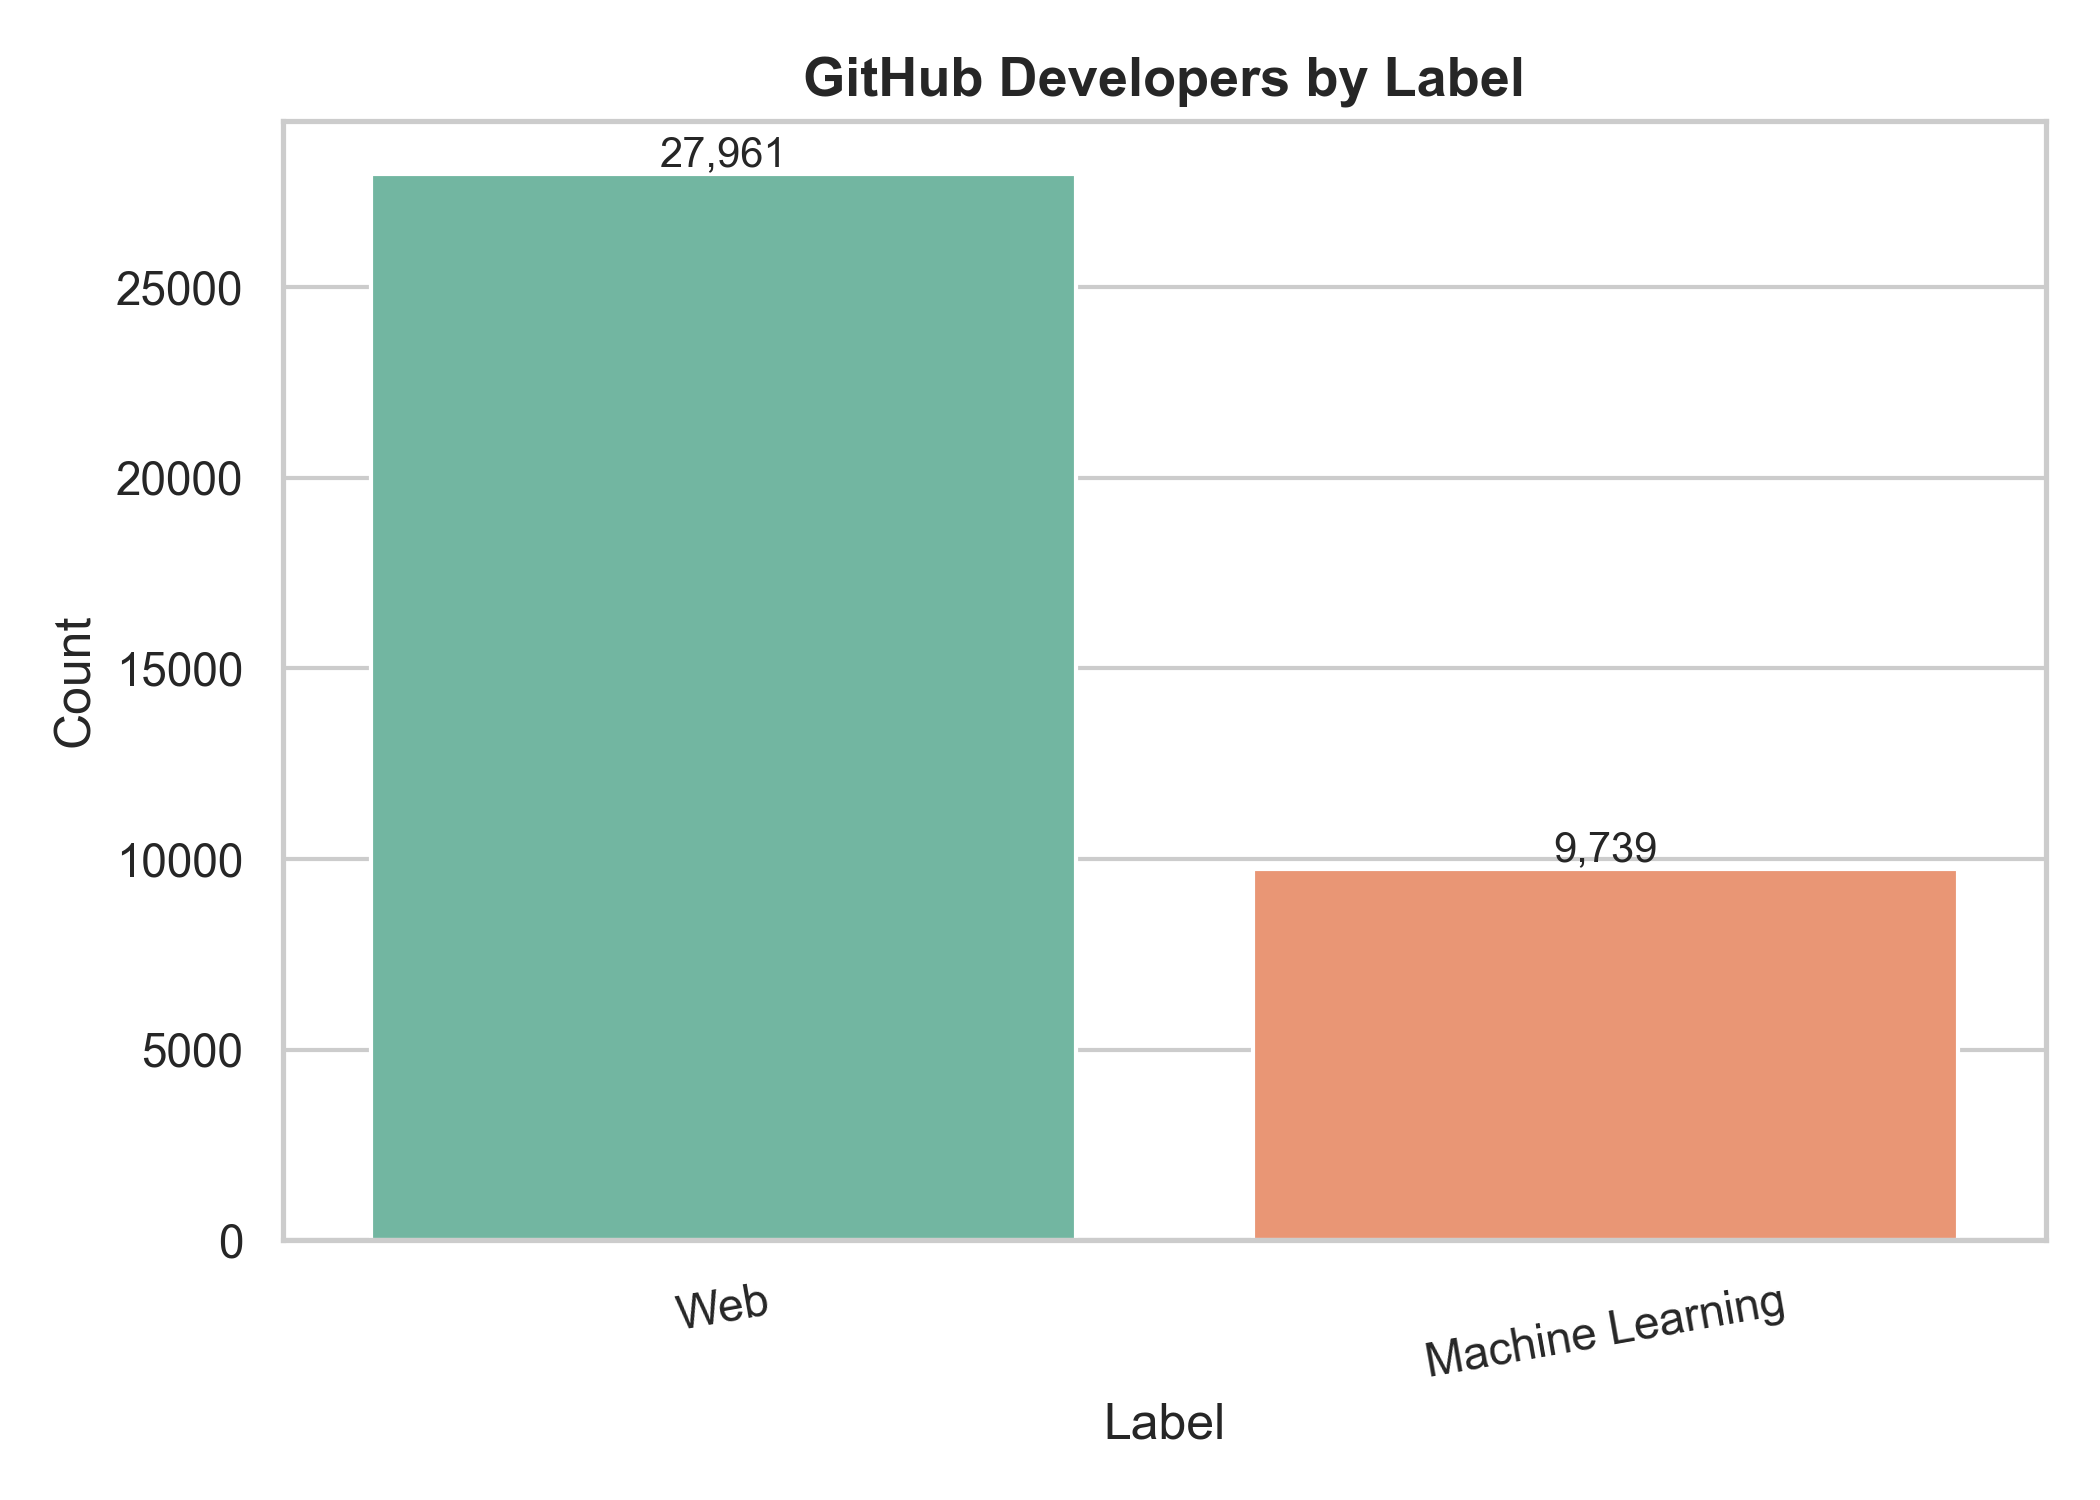

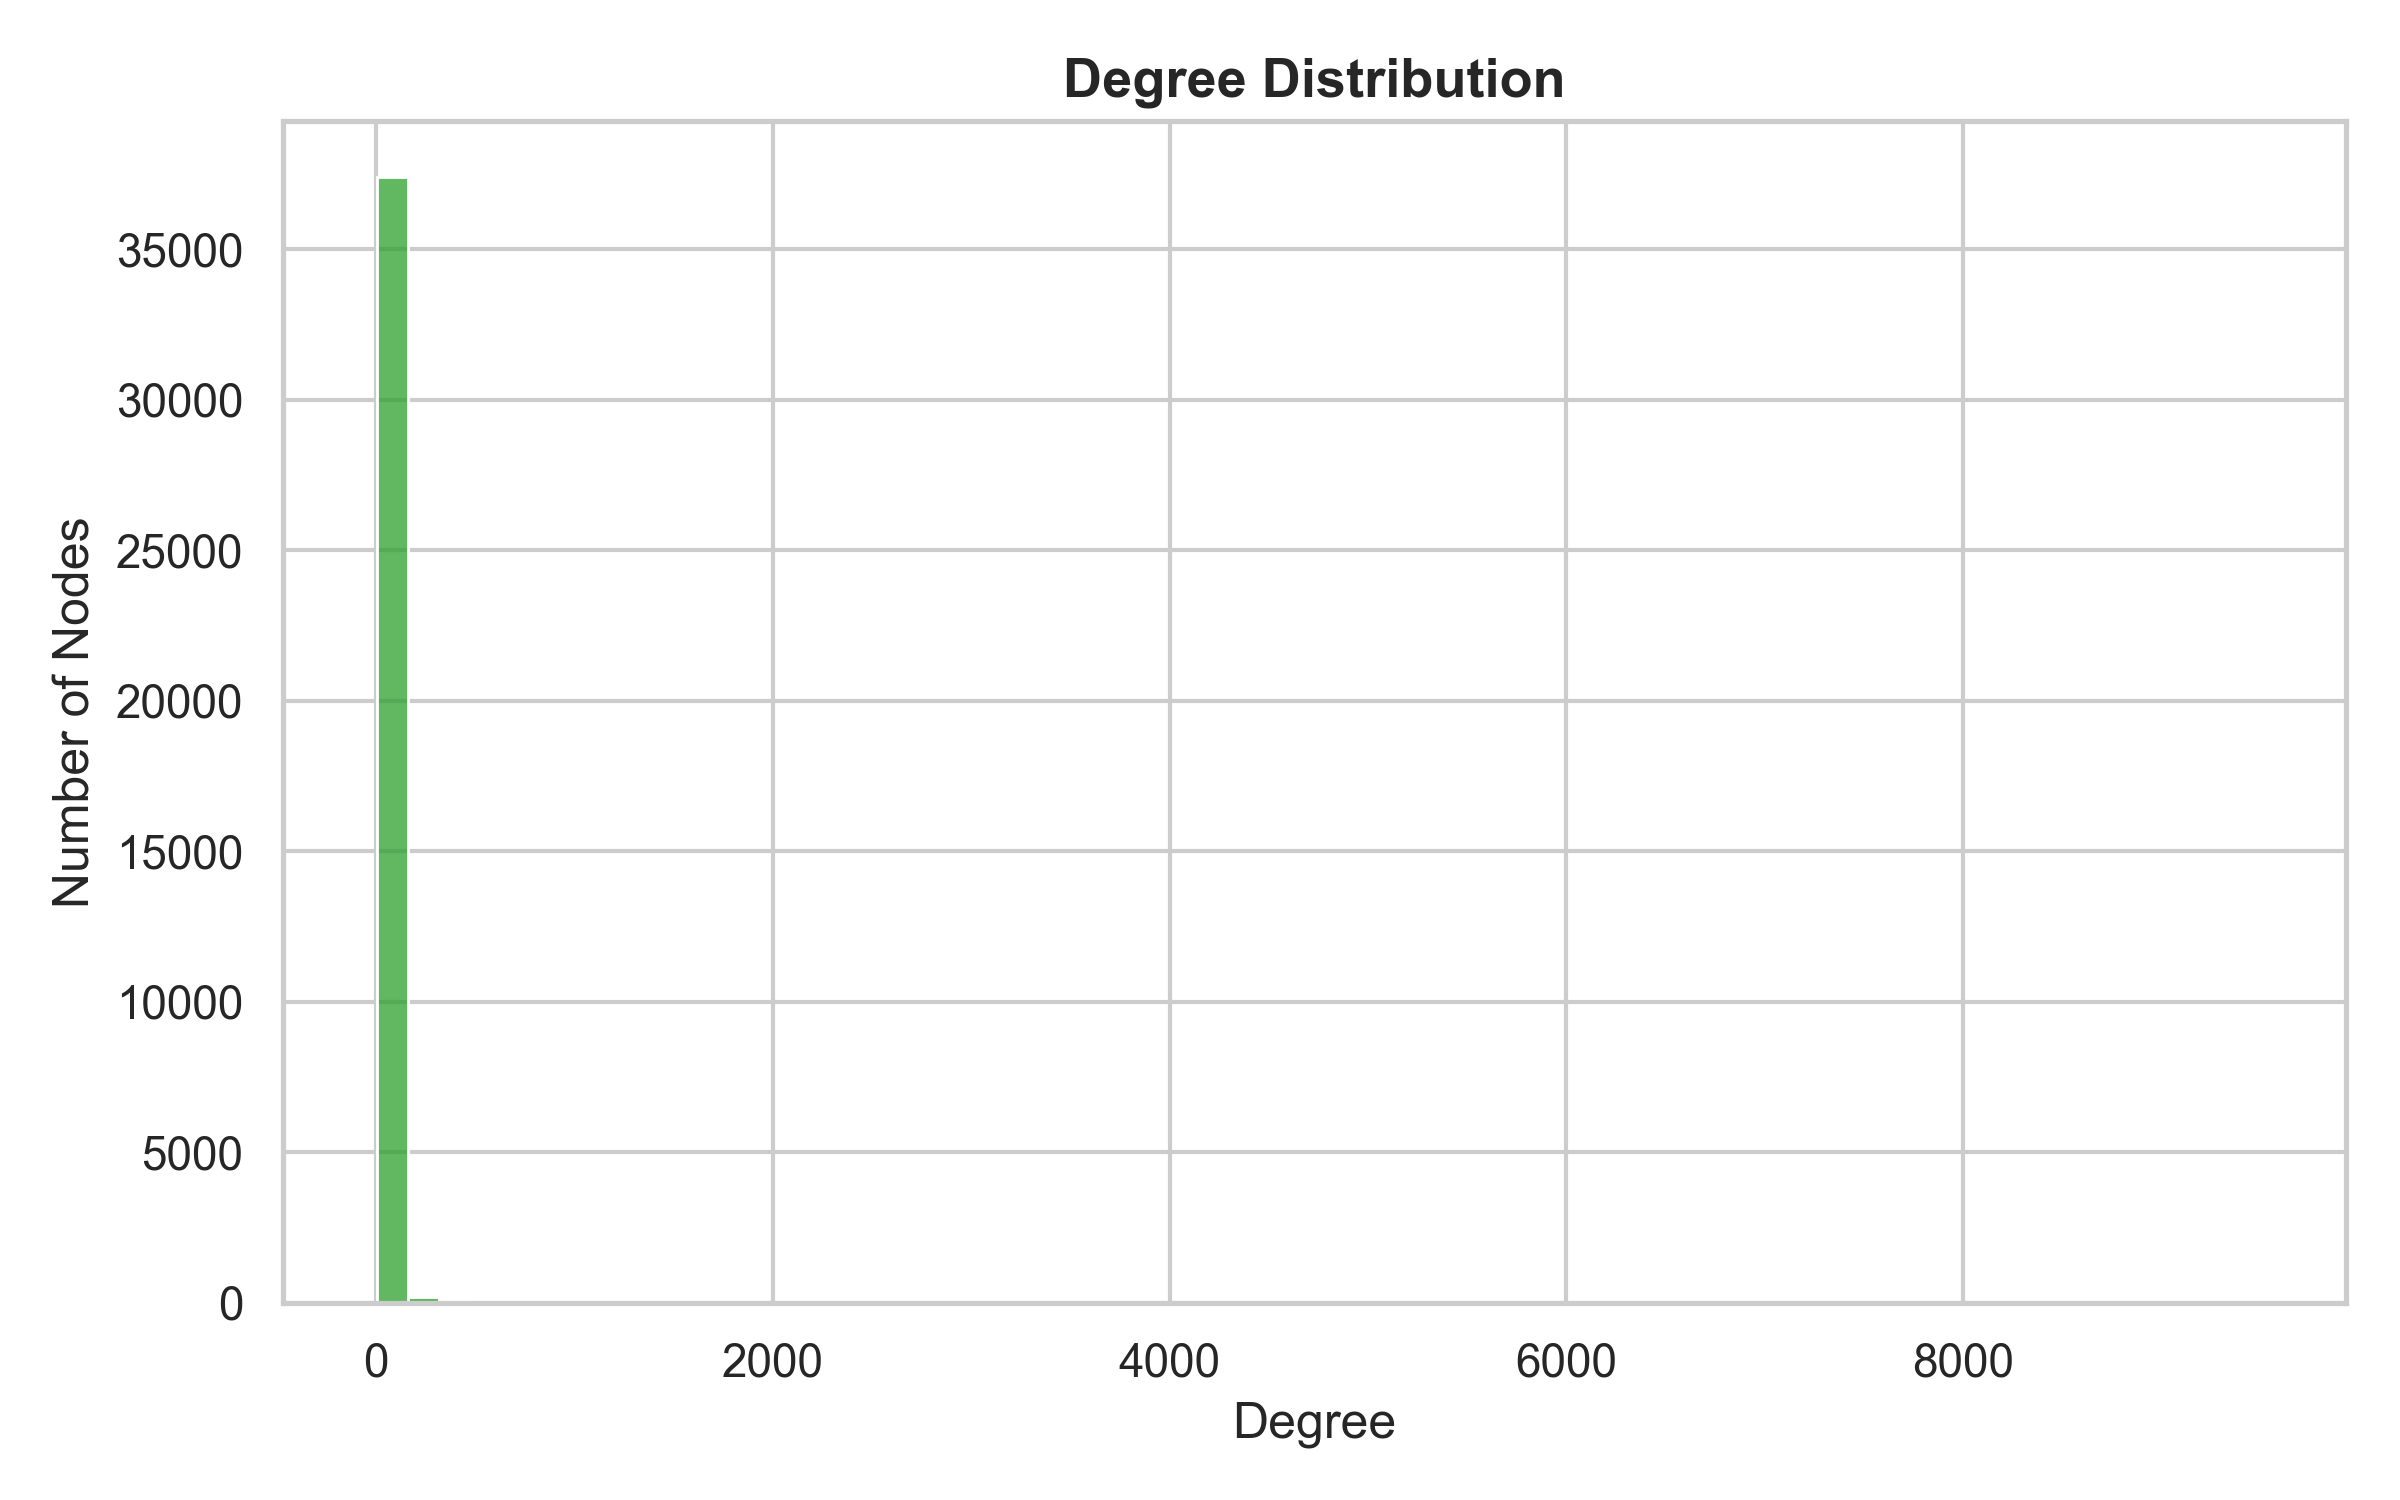

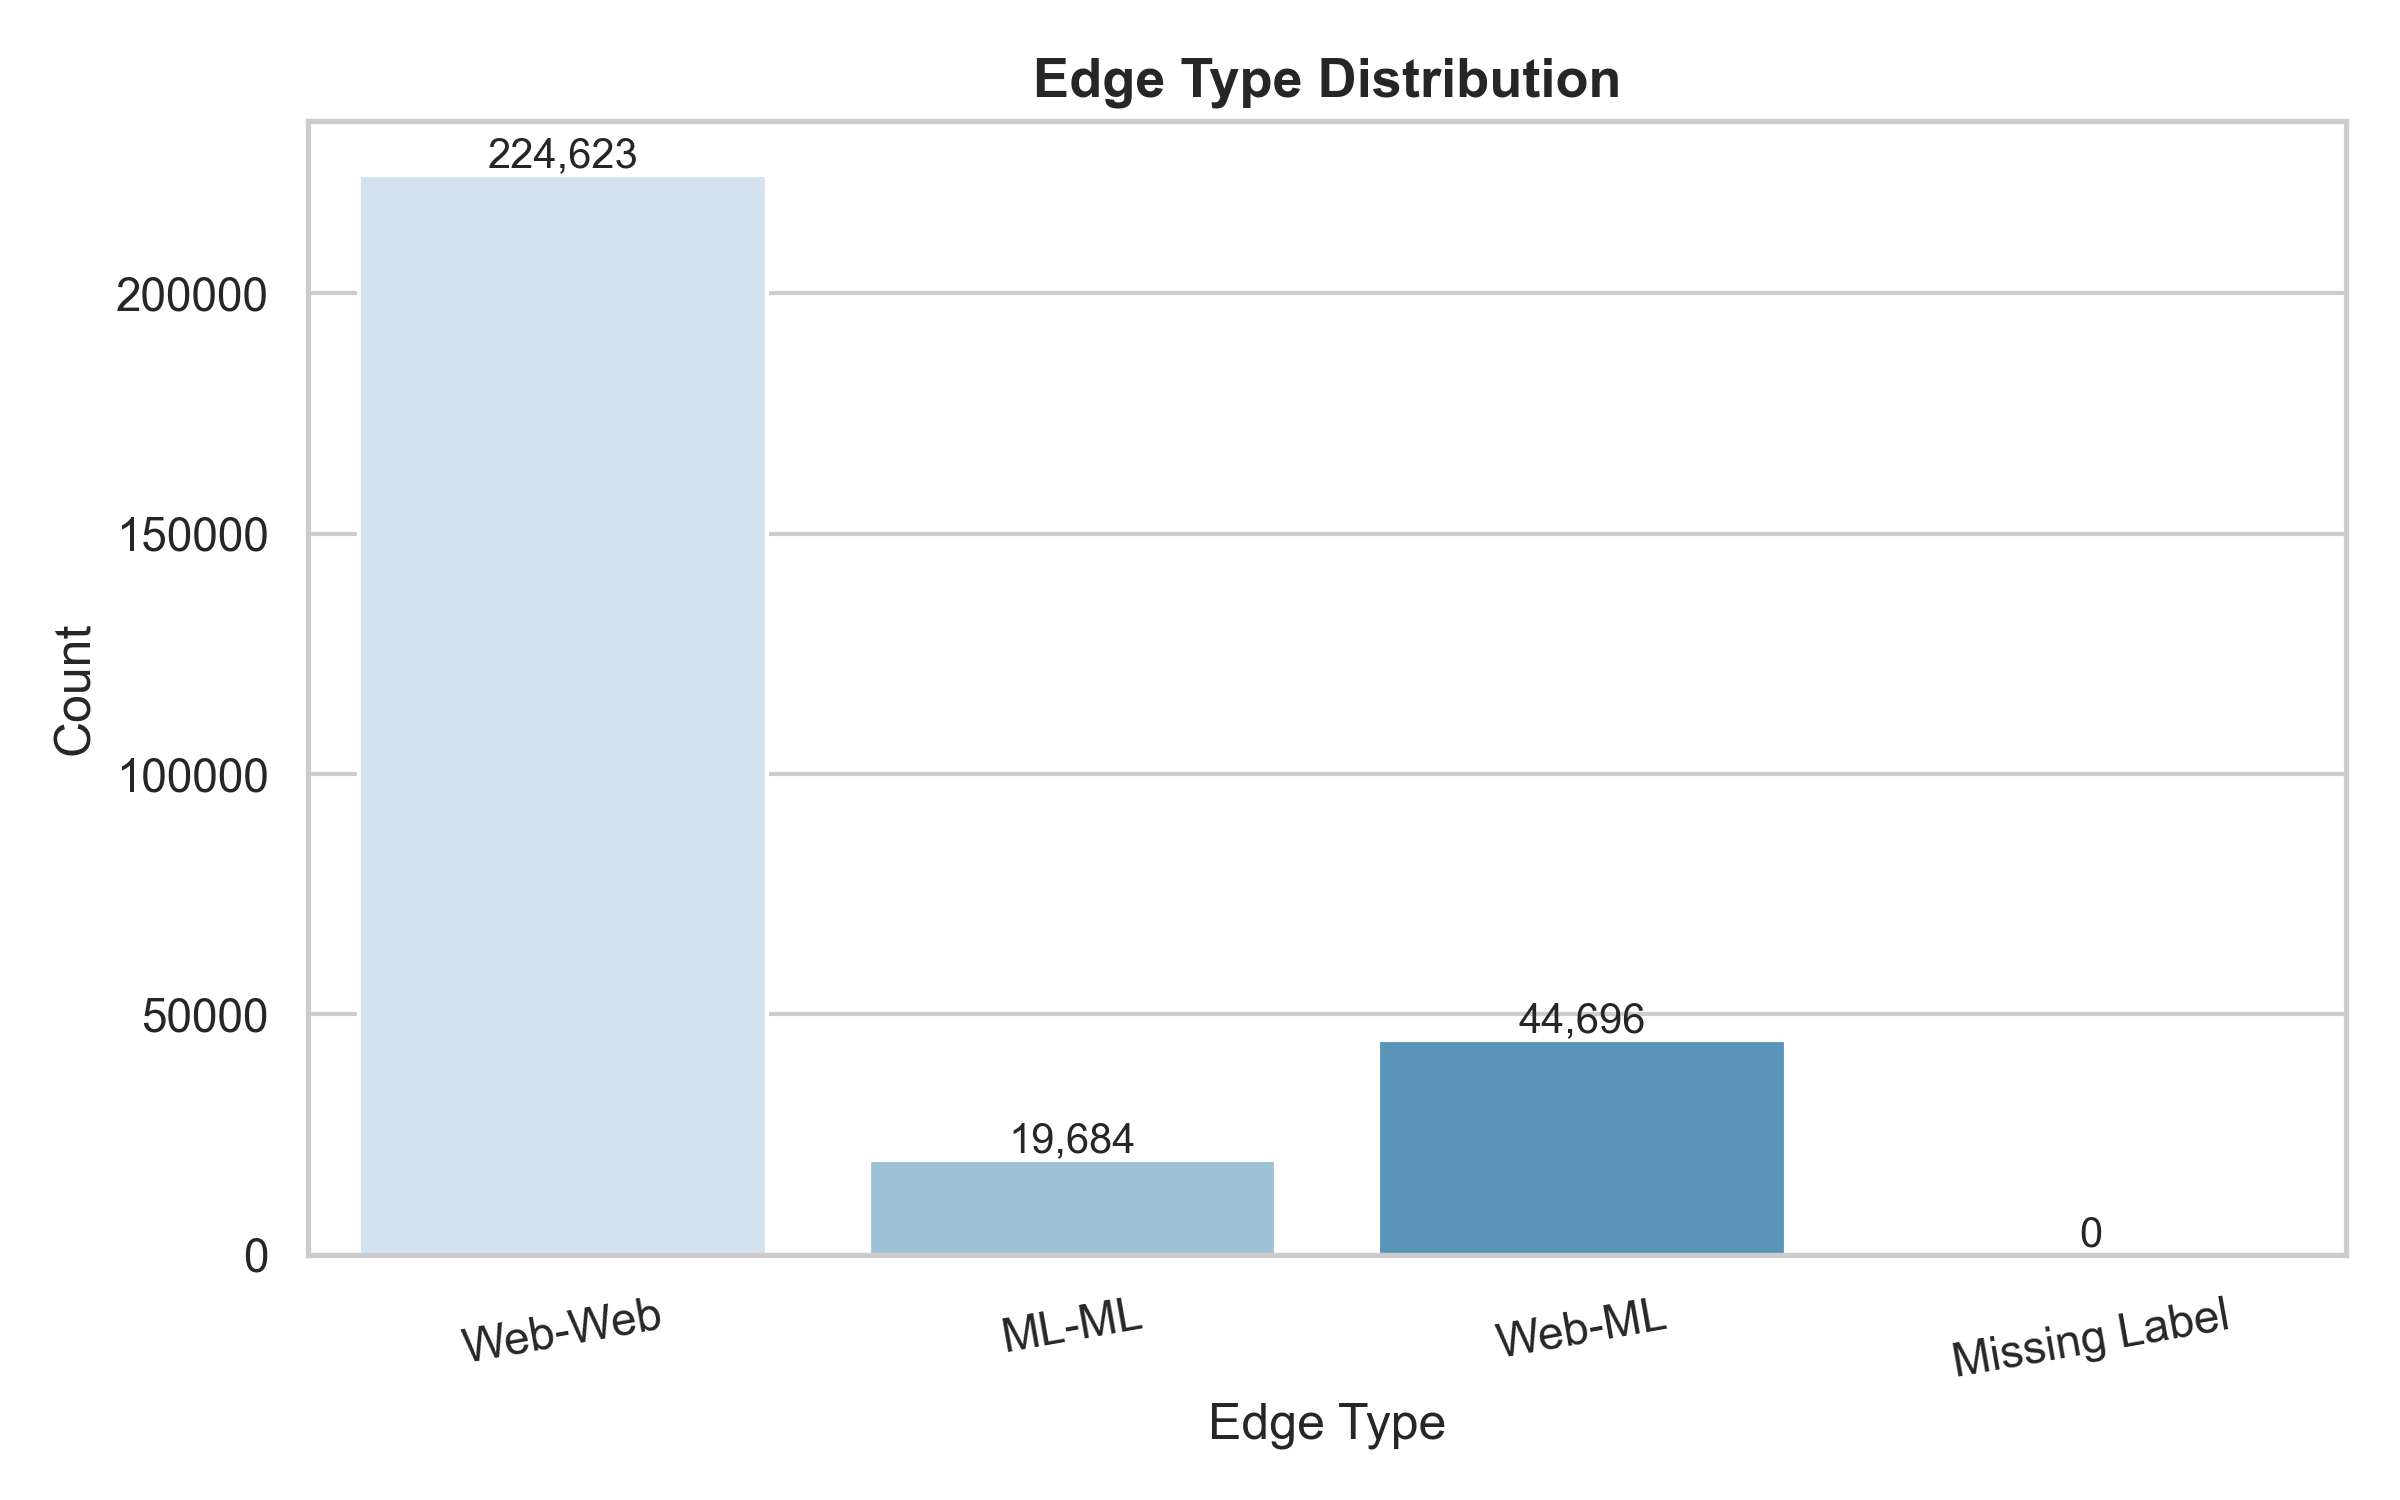

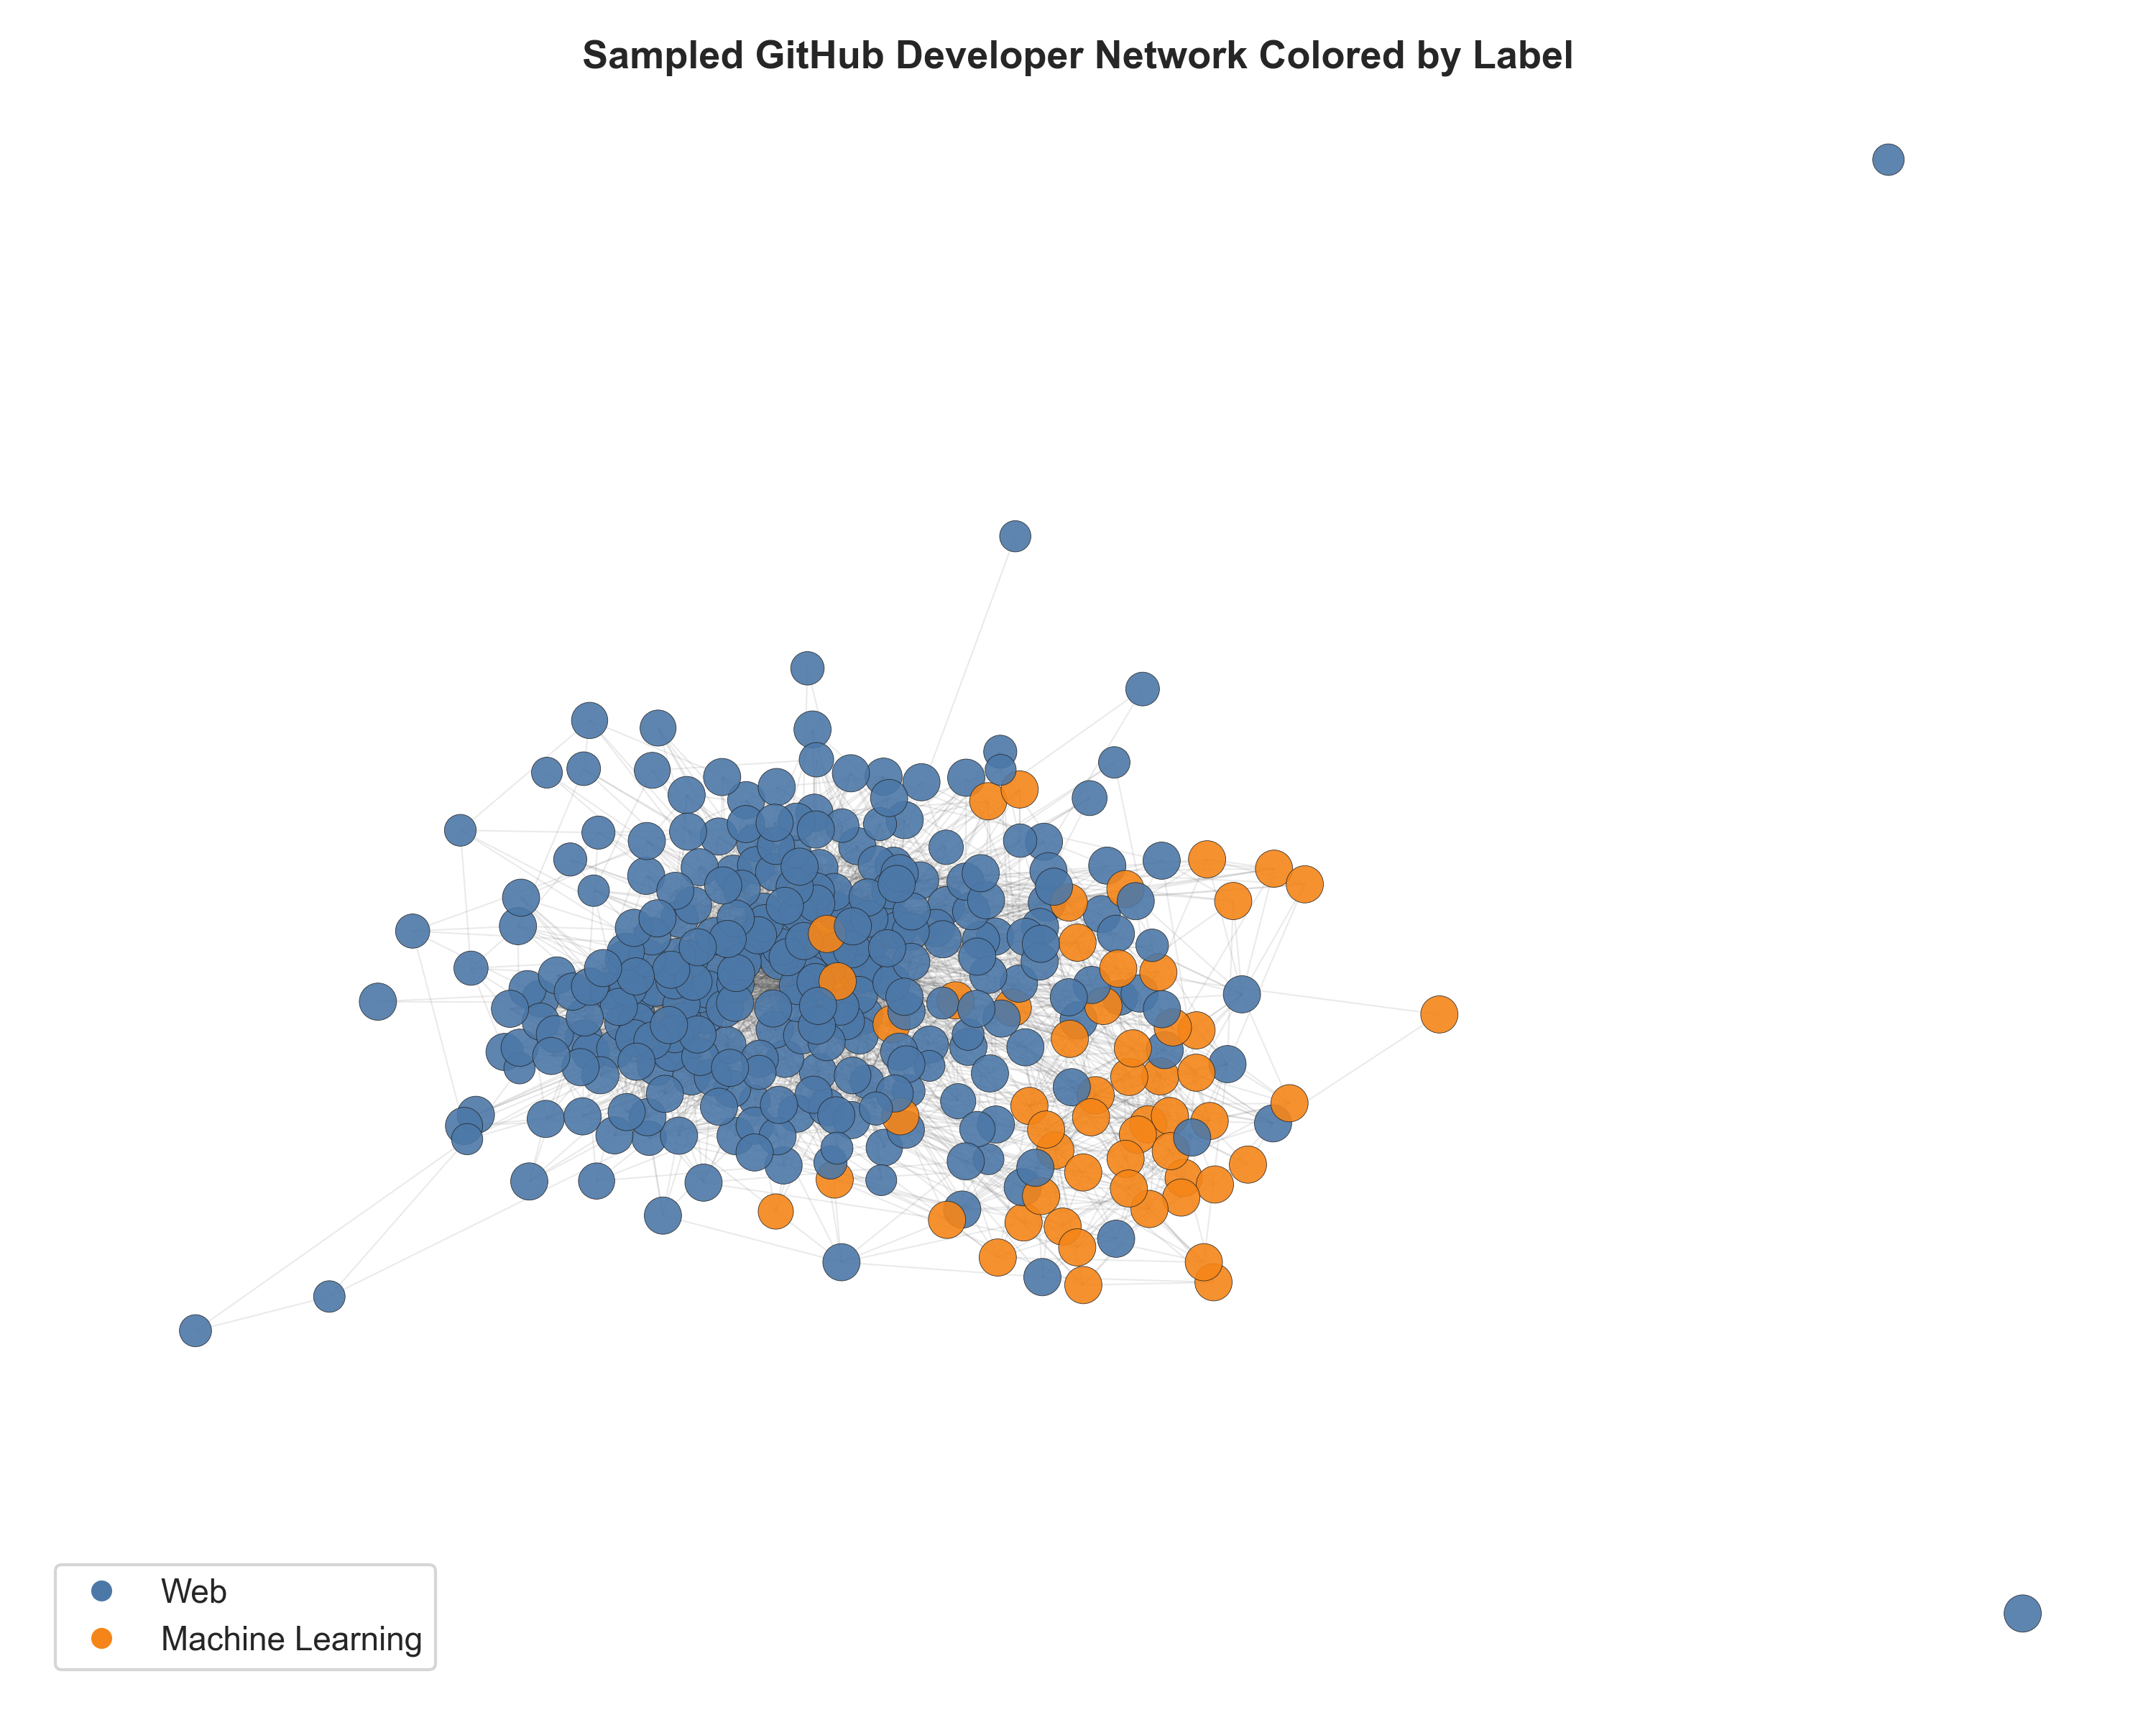

In [4]:
for filename in (
    "label_distribution.png",
    "degree_distribution.png",
    "edge_type_distribution.png",
    "sampled_network_by_label.png",
):
    display(Image(filename=str(ROOT / "outputs/figures" / filename)))


The sampled network is a qualitative view only. Quantitative claims come from the full graph and the reported tables.

## Summary

The graph is sparse, connected, heterogeneous in degree, and strongly assortative by the observed field label. Notebook 04 examines whether this structure also appears at the community level.
